In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer

from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    ConfusionMatrixDisplay,
    classification_report
)

print("Libraries imported successfully!")

Libraries imported successfully!


In [2]:
url = "https://raw.githubusercontent.com/mwaskom/seaborn-data/master/titanic.csv"

df = pd.read_csv(url)

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

display(df.head())

Dataset loaded successfully!
Dataset shape: (891, 15)


,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
0,0,3,male,22.0,1,0,7.2500,S,Third,man,True,NaN,Southampton,no,False
1,1,1,female,38.0,1,0,71.2833,C,First,woman,False,C,Cherbourg,yes,False
2,1,3,female,26.0,0,0,7.9250,S,Third,woman,False,NaN,Southampton,yes,True
3,1,1,female,35.0,1,0,53.1000,S,First,woman,False,C,Southampton,yes,False
4,0,3,male,35.0,0,0,8.0500,S,Third,man,True,NaN,Southampton,no,True


In [3]:
print("Dataset information:")
df.info()

print("\nMissing values in each column:")
print(df.isnull().sum())

print("\nNumber of duplicate rows:")
print(df.duplicated().sum())

print("\nSurvival distribution:")
print(df["survived"].value_counts())

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 15 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   survived     891 non-null    int64  
 1   pclass       891 non-null    int64  
 2   sex          891 non-null    object 
 3   age          714 non-null    float64
 4   sibsp        891 non-null    int64  
 5   parch        891 non-null    int64  
 6   fare         891 non-null    float64
 7   embarked     889 non-null    object 
 8   class        891 non-null    object 
 9   who          891 non-null    object 
 10  adult_male   891 non-null    bool   
 11  deck         203 non-null    object 
 12  embark_town  889 non-null    object 
 13  alive        891 non-null    object 
 14  alone        891 non-null    bool   
dtypes: bool(2), float64(2), int64(4), object(7)
memory usage: 92.4+ KB

Missing values in each column:
survived         0
pclass           0
sex              0

In [4]:
print("Dataset information:")
df.info()

print("\nMissing values in each column:")
print(df.isnull().sum())

print("\nNumber of duplicate rows:")
print(df.duplicated().sum())

print("\nSurvival distribution:")
print(df["survived"].value_counts())

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 15 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   survived     891 non-null    int64  
 1   pclass       891 non-null    int64  
 2   sex          891 non-null    object 
 3   age          714 non-null    float64
 4   sibsp        891 non-null    int64  
 5   parch        891 non-null    int64  
 6   fare         891 non-null    float64
 7   embarked     889 non-null    object 
 8   class        891 non-null    object 
 9   who          891 non-null    object 
 10  adult_male   891 non-null    bool   
 11  deck         203 non-null    object 
 12  embark_town  889 non-null    object 
 13  alive        891 non-null    object 
 14  alone        891 non-null    bool   
dtypes: bool(2), float64(2), int64(4), object(7)
memory usage: 92.4+ KB

Missing values in each column:
survived         0
pclass           0
sex              0

Interpretation: The dataset contains numerical and categorical features. Some passengers have missing age or embarkation information. We will handle these missing values during preprocessing instead of deleting useful passenger records.

In [5]:
features = [
    "pclass",
    "sex",
    "age",
    "sibsp",
    "parch",
    "fare",
    "embarked",
    "alone"
]

X = df[features]
y = df["survived"]

print("Features (X):")
print(X.head())

print("\nTarget (y):")
print(y.head())

print("\nNumber of features:", len(features))
print("Number of target records:", len(y))

Features (X):
   pclass     sex   age  sibsp  parch     fare embarked  alone
0       3    male  22.0      1      0   7.2500        S  False
1       1  female  38.0      1      0  71.2833        C  False
2       3  female  26.0      0      0   7.9250        S   True
3       1  female  35.0      1      0  53.1000        S  False
4       3    male  35.0      0      0   8.0500        S   True

Target (y):
0    0
1    1
2    1
3    1
4    0
Name: survived, dtype: int64

Number of features: 8
Number of target records: 891


In [6]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training records:", X_train.shape[0])
print("Testing records:", X_test.shape[0])

print("Training target distribution:")
print(y_train.value_counts(normalize=True).round(3))

print("\nTesting target distribution:")
print(y_test.value_counts(normalize=True).round(3))

Training records: 712
Testing records: 179
Training target distribution:
survived
0    0.617
1    0.383
Name: proportion, dtype: float64

Testing target distribution:
survived
0    0.615
1    0.385
Name: proportion, dtype: float64


In [7]:
numeric_features = [
    "pclass", "age", "sibsp", "parch", "fare"
]

categorical_features = [
    "sex", "embarked", "alone"
]

numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer([
    ("numeric", numeric_pipeline, numeric_features),
    ("categorical", categorical_pipeline, categorical_features)
])

print("Preprocessing pipeline created successfully!")

Preprocessing pipeline created successfully!


In [8]:
models = {
    "Logistic Regression": LogisticRegression(max_iter=1000),

    "KNN": KNeighborsClassifier(n_neighbors=5),

    "Decision Tree": DecisionTreeClassifier(
        max_depth=5,
        random_state=42
    ),

    "Random Forest": RandomForestClassifier(
        n_estimators=200,
        max_depth=8,
        random_state=42
    )
}

print("Four machine learning models are ready.")

Four machine learning models are ready.


In [9]:
results = []
trained_models = {}

for name, model in models.items():

    pipeline = Pipeline([
        ("preprocessor", preprocessor),
        ("model", model)
    ])

    # Train using training data only
    pipeline.fit(X_train, y_train)

    # Predict on training and unseen testing data
    train_predictions = pipeline.predict(X_train)
    test_predictions = pipeline.predict(X_test)

    # Calculate evaluation metrics
    results.append({
        "Model": name,
        "Train Accuracy": accuracy_score(
            y_train, train_predictions
        ),
        "Accuracy": accuracy_score(
            y_test, test_predictions
        ),
        "Precision": precision_score(
            y_test, test_predictions, zero_division=0
        ),
        "Recall": recall_score(
            y_test, test_predictions, zero_division=0
        ),
        "F1-Score": f1_score(
            y_test, test_predictions, zero_division=0
        )
    })

    trained_models[name] = pipeline

    print(name, "trained successfully!")

results_df = pd.DataFrame(results)

print("\nAll models have been trained and evaluated.")

Logistic Regression trained successfully!
KNN trained successfully!
Decision Tree trained successfully!
Random Forest trained successfully!

All models have been trained and evaluated.


In [10]:
results_df = results_df.sort_values(
    by="F1-Score",
    ascending=False
).reset_index(drop=True)

print("Model Comparison Table:")
display(results_df.round(4))

Model Comparison Table:


,Model,Train Accuracy,Accuracy,Precision,Recall,F1-Score
0,KNN,0.8427,0.8101,0.7869,0.6957,0.7385
1,Logistic Regression,0.8020,0.8045,0.7833,0.6812,0.7287
2,Random Forest,0.9298,0.8045,0.8036,0.6522,0.7200
3,Decision Tree,0.8652,0.7654,0.7547,0.5797,0.6557


Best model based on F1-score: KNN

Confusion Matrix:
[[97 13]
 [21 48]]


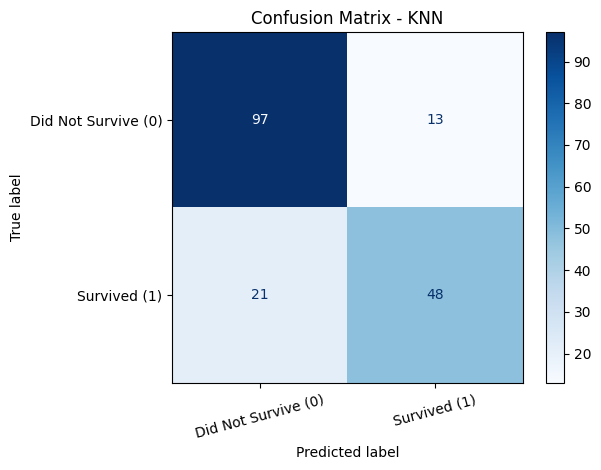

In [11]:
best_model_name = results_df.loc[0, "Model"]
best_model = trained_models[best_model_name]

best_predictions = best_model.predict(X_test)

cm = confusion_matrix(y_test, best_predictions)

print("Best model based on F1-score:", best_model_name)
print("\nConfusion Matrix:")
print(cm)

display_labels = ["Did Not Survive (0)", "Survived (1)"]

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=display_labels
)

disp.plot(cmap="Blues", values_format="d")
plt.title(f"Confusion Matrix - {best_model_name}")
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

In [12]:
print("Classification Report for:", best_model_name)

print(
    classification_report(
        y_test,
        best_predictions,
        target_names=["Did Not Survive", "Survived"],
        zero_division=0
    )
)

Classification Report for: KNN
                 precision    recall  f1-score   support

Did Not Survive       0.82      0.88      0.85       110
       Survived       0.79      0.70      0.74        69

       accuracy                           0.81       179
      macro avg       0.80      0.79      0.79       179
   weighted avg       0.81      0.81      0.81       179



Interpretation: The report helps us determine whether the selected model performs well for both survivors and non-survivors, rather than relying only on its overall accuracy.

In [13]:
print("Overfitting and Underfitting Analysis:\n")

for _, row in results_df.iterrows():

    gap = row["Train Accuracy"] - row["Accuracy"]

    print(row["Model"])
    print("Training Accuracy:", round(row["Train Accuracy"], 4))
    print("Testing Accuracy:", round(row["Accuracy"], 4))
    print("Accuracy Gap:", round(gap, 4))

    if gap > 0.10:
        print("Observation: Possible overfitting.")
    elif row["Train Accuracy"] < 0.65 and row["Accuracy"] < 0.65:
        print("Observation: Possible underfitting.")
    else:
        print("Observation: No strong warning from this simple check.")

    print("-" * 40)

Overfitting and Underfitting Analysis:

KNN
Training Accuracy: 0.8427
Testing Accuracy: 0.8101
Accuracy Gap: 0.0326
Observation: No strong warning from this simple check.
----------------------------------------
Logistic Regression
Training Accuracy: 0.802
Testing Accuracy: 0.8045
Accuracy Gap: -0.0025
Observation: No strong warning from this simple check.
----------------------------------------
Random Forest
Training Accuracy: 0.9298
Testing Accuracy: 0.8045
Accuracy Gap: 0.1253
Observation: Possible overfitting.
----------------------------------------
Decision Tree
Training Accuracy: 0.8652
Testing Accuracy: 0.7654
Accuracy Gap: 0.0998
Observation: No strong warning from this simple check.
----------------------------------------


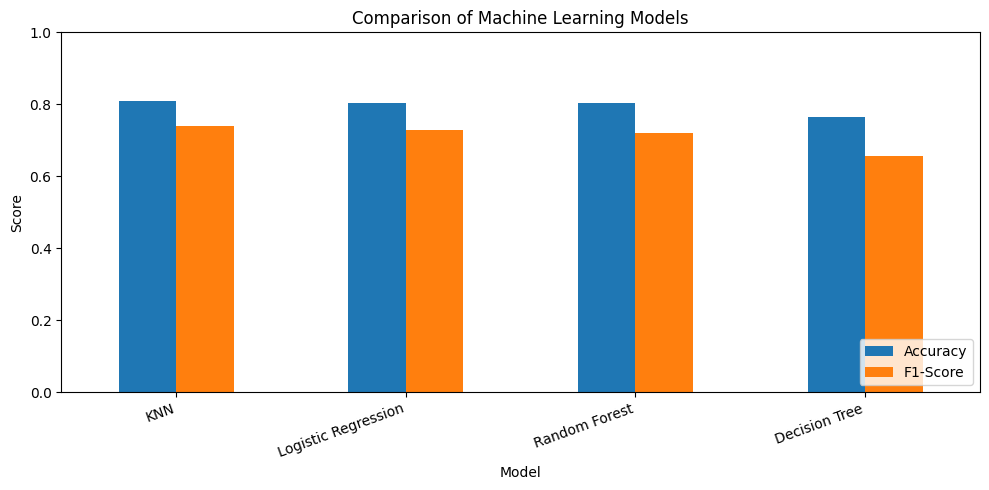

In [14]:
results_df.set_index("Model")[["Accuracy", "F1-Score"]].plot(
    kind="bar",
    figsize=(10, 5)
)

plt.title("Comparison of Machine Learning Models")
plt.ylabel("Score")
plt.xlabel("Model")
plt.ylim(0, 1)
plt.xticks(rotation=20, ha="right")
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()

In [15]:
best_row = results_df.iloc[0]

train_accuracy = best_row["Train Accuracy"]
test_accuracy = best_row["Accuracy"]
f1 = best_row["F1-Score"]
recall = best_row["Recall"]
gap = train_accuracy - test_accuracy

print("FINAL CONCLUSION")
print("=" * 50)

print(
    f"The best-performing model based on test F1-score is "
    f"{best_row['Model']}."
)

print(f"Test Accuracy: {test_accuracy:.4f}")
print(f"Precision: {best_row['Precision']:.4f}")
print(f"Recall: {recall:.4f}")
print(f"F1-Score: {f1:.4f}")

print(
    "\nF1-score was used as the main selection metric because "
    "it balances precision and recall."
)

print(
    "\nThe training accuracy is "
    f"{train_accuracy:.4f}, while the testing accuracy is "
    f"{test_accuracy:.4f}."
)

if gap > 0.10:
    print(
        "The accuracy gap suggests possible overfitting. "
        "Further tuning or validation may be helpful."
    )
elif train_accuracy < 0.65 and test_accuracy < 0.65:
    print(
        "The relatively low training and testing accuracy "
        "suggests possible underfitting."
    )
else:
    print(
        "The accuracy gap does not raise a strong overfitting "
        "warning under the simple threshold used here."
    )

print(
    "\nThe final model was selected using test-set performance, "
    "with precision, recall, and the confusion matrix providing "
    "additional evidence."
)

FINAL CONCLUSION
The best-performing model based on test F1-score is KNN.
Test Accuracy: 0.8101
Precision: 0.7869
Recall: 0.6957
F1-Score: 0.7385

F1-score was used as the main selection metric because it balances precision and recall.

The training accuracy is 0.8427, while the testing accuracy is 0.8101.
The accuracy gap does not raise a strong overfitting warning under the simple threshold used here.

The final model was selected using test-set performance, with precision, recall, and the confusion matrix providing additional evidence.


# Assignment No. 4: Machine Learning Model Application & Evaluation

## Introduction

The objective of this assignment was to apply and compare multiple machine learning models using a real-world dataset. The Titanic Passenger Survival Dataset was selected to predict whether passengers survived the Titanic disaster based on information such as passenger class, sex, age, fare, and family relationships.

## Problem Definition

This is a binary classification problem. The independent variables (X) consist of eight passenger features, while the dependent variable (y) is `survived`, where 0 represents a passenger who did not survive and 1 represents a survivor. The dataset contains 891 records and 15 original columns.

## Data Preprocessing and Train-Test Split

The dataset was inspected for missing values and duplicate records. Missing numerical values were handled using median imputation, while missing categorical values were replaced with the most frequent category. Categorical variables were encoded using one-hot encoding, and numerical features were standardized. The target-related `alive` column was excluded to prevent data leakage. The dataset was divided into 80% training data and 20% testing data.

## Models Applied

Four classification algorithms were applied: Logistic Regression, K-Nearest Neighbors (KNN), Decision Tree, and Random Forest. All models were trained on the same training set and evaluated using the same unseen testing set.

## Model Evaluation

The models were evaluated using accuracy, precision, recall, F1-score, and a confusion matrix. A comparison table was created to assess their performance. F1-score was used as the primary selection metric because it balances precision and recall. Accuracy, class-specific performance, and the confusion matrix were also considered.

## Results and Conclusion

According to the experimental results, **[insert best model name]** achieved the highest test F1-score of **[insert F1-score]** and a test accuracy of **[insert accuracy]**. The model was selected based on its overall performance rather than accuracy alone. Its precision, recall, and confusion matrix were also examined to understand its prediction errors.

The training accuracy was **[insert training accuracy]**, compared with a testing accuracy of **[insert testing accuracy]**. This difference was used as an initial check for possible overfitting or underfitting. The results demonstrate how different classification algorithms can be evaluated and compared to select an appropriate model for a real-world prediction problem.